<a href="https://colab.research.google.com/github/jessicalewinter/deep-learning-specialization/blob/main/course-notebooks/deep-architectures/challenge_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Esse notebook carrega o dataset Rock, Paper, Scissors do Tensorflow e compara o modelo MLP com o CNN analisando a acurácia e a loss

**Aluna:** Jessica Matias Lewinter

In [10]:
# Carrega todas as libs necessárias
!pip install -q importlib_resources

import tensorflow as tf
import tensorflow_datasets as tfds
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Conv2D, MaxPool2D, Flatten, Dropout, BatchNormalization

In [11]:
# Preprocess directly to 64x64
def preprocess_64(image, label):
    image = tf.image.resize(image, (64, 64))
    image = tf.image.rgb_to_grayscale(image)
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

ds_train = tfds.load('rock_paper_scissors', split='train', as_supervised=True)
ds_valid = tfds.load('rock_paper_scissors', split='test', as_supervised=True)



In [12]:
x_train = np.array([img.numpy() for img, lbl in ds_train.map(preprocess_64)])
y_train = np.array([lbl.numpy() for img, lbl in ds_train.map(preprocess_64)])

x_valid = np.array([img.numpy() for img, lbl in ds_valid.map(preprocess_64)])
y_valid = np.array([lbl.numpy() for img, lbl in ds_valid.map(preprocess_64)])


num_classes = 3
EPOCHS=20
BATCH_SIZE=32
y_train = tf.keras.utils.to_categorical(y_train, num_classes)
y_valid = tf.keras.utils.to_categorical(y_valid, num_classes)

print(f"Train images shape: {x_train.shape}")
print(f"Validation images shape: {x_valid.shape}")

Train images shape: (2520, 64, 64, 1)
Validation images shape: (372, 64, 64, 1)


In [13]:
## Cria o MLP com duas camadas internas
x_train_flat = x_train.reshape(-1, 64 * 64 * 1)
x_valid_flat = x_valid.reshape(-1, 64 * 64 * 1)

model_mlp = Sequential([
    Input(shape=(4096,)),
    Dense(units=512, activation="relu"),
    Dense(units=512, activation="relu"),
    Dense(units=num_classes, activation="softmax")
])

model_mlp.summary()
model_mlp.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_5 (Dense)                 │ (None, 512)            │     2,097,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 3)              │         1,539 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,361,859 (9.01 MB)

 Trainable params: 2,361,859 (9.01 MB)

 Non-trainable params: 0 (0.00 B)

In [14]:
# Treina o modelo MLP
model_history_mlp = model_mlp.fit(
    x_train_flat,
    y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(x_valid_flat, y_valid)
)

Epoch 1/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - accuracy: 0.5099 - loss: 1.4085 - val_accuracy: 0.5269 - val_loss: 1.0089
Epoch 2/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7921 - loss: 0.5411 - val_accuracy: 0.5188 - val_loss: 1.1339
Epoch 3/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8607 - loss: 0.3754 - val_accuracy: 0.5833 - val_loss: 1.2790
Epoch 4/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8488 - loss: 0.3924 - val_accuracy: 0.4651 - val_loss: 1.3795
Epoch 5/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9194 - loss: 0.2389 - val_accuracy: 0.6478 - val_loss: 1.8946
Epoch 6/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9464 - loss: 0.1630 - val_accuracy: 0.5565 - val_loss: 2.2474
Epoch 7/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9361 - loss: 0.1728 - val_accuracy: 0.6237 - val_loss: 1.7393
Epoch 8/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9865 - loss: 0.0584 - val_accuracy: 0.6613 - val_loss

In [15]:
## Create the Convolutional Model
model_cnn = Sequential([
    Input(shape=(64, 64, 1)),
    Conv2D(32, (3, 3), padding='same', activation='relu'),
    MaxPool2D((2, 2)),
    Conv2D(64, (3, 3), strides=1, padding='same', activation='relu'),
    MaxPool2D((2, 2), strides=2, padding="same"),
    Conv2D(32, (3, 3), strides=1, padding='same', activation='relu'),
    MaxPool2D((2, 2), strides=2, padding="same"),
    Flatten(),
    Dense(units=128, activation='relu'),
    Dense(units=num_classes, activation='softmax')
])

model_cnn.summary()
model_cnn.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 16, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 8, 8, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 299,939 (1.14 MB)

 Trainable params: 299,939 (1.14 MB)

 Non-trainable params: 0 (0.00 B)

In [16]:
# Treina o modelo CNN
model_history_cnn = model_cnn.fit(
    x_train,
    y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(x_valid, y_valid)
)

Epoch 1/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 11s 72ms/step - accuracy: 0.7091 - loss: 0.6287 - val_accuracy: 0.8898 - val_loss: 0.3313
Epoch 2/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9889 - loss: 0.0570 - val_accuracy: 0.7446 - val_loss: 0.7201
Epoch 3/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9964 - loss: 0.0157 - val_accuracy: 0.9328 - val_loss: 0.1869
Epoch 4/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9988 - loss: 0.0044 - val_accuracy: 0.9274 - val_loss: 0.2065
Epoch 5/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 1.0000 - loss: 0.0018 - val_accuracy: 0.9167 - val_loss: 0.2147
Epoch 6/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 1.0000 - loss: 0.0013 - val_accuracy: 0.8790 - val_loss: 0.2431
Epoch 7/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 1.0000 - loss: 6.8393e-04 - val_accuracy: 0.8925 - val_loss: 0.2273
Epoch 8/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 1.0000 - loss: 4.1566e-04 - val_accuracy: 0.8844 -

### Comparação CNN vs MLP

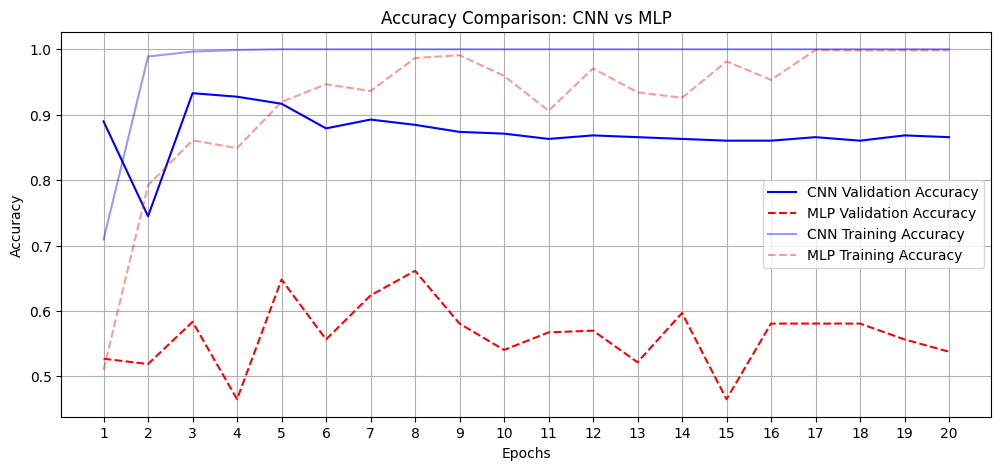

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Plot Validation Accuracy
plt.plot(model_history_cnn.history['val_accuracy'], label='CNN Validation Accuracy', color='blue', linestyle='-')
plt.plot(model_history_mlp.history['val_accuracy'], label='MLP Validation Accuracy', color='red', linestyle='--')

# Plot Training Accuracy
plt.plot(model_history_cnn.history['accuracy'], label='CNN Training Accuracy', color='blue', alpha=0.4, linestyle='-')
plt.plot(model_history_mlp.history['accuracy'], label='MLP Training Accuracy', color='red', alpha=0.4, linestyle='--')
plt.xticks(range(len(model_history_cnn.history['accuracy'])), [f"{i+1}" for i in range(len(model_history_cnn.history['accuracy']))])
plt.title('Accuracy Comparison: CNN vs MLP')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

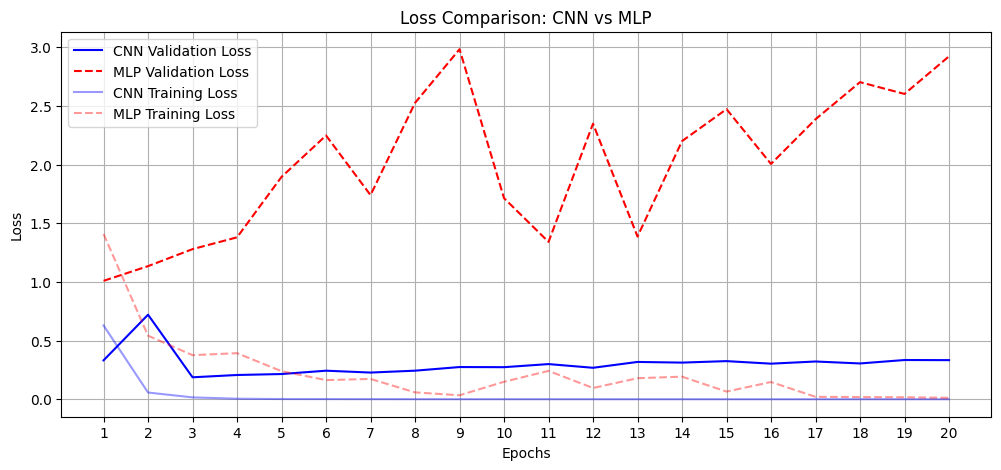

In [22]:

plt.figure(figsize=(12, 5))

# Plot Validation Accuracy
plt.plot(model_history_cnn.history['val_loss'], label='CNN Validation Loss', color='blue', linestyle='-')
plt.plot(model_history_mlp.history['val_loss'], label='MLP Validation Loss', color='red', linestyle='--')

# Plot Training Accuracy
plt.plot(model_history_cnn.history['loss'], label='CNN Training Loss', color='blue', alpha=0.4, linestyle='-')
plt.plot(model_history_mlp.history['loss'], label='MLP Training Loss', color='red', alpha=0.4, linestyle='--')
plt.xticks(range(len(model_history_cnn.history['loss'])), [f"{i+1}" for i in range(len(model_history_cnn.history['loss']))])
plt.title('Loss Comparison: CNN vs MLP')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

## Análise
Conforme visto nos gráficos acima, o modelo CNN chega em uma acurácia de 100% nas primeiras épocas e manteem uma alta acurácia de validação(86% a 93%). Isso se deve ao fato de que as camadas de Conv2D são eficazes ao capturar formas geométricas, o que consegue distinguir entre os tipos(rock,paper e scissors).

No modelo MLP, vemos um clássico *overfitting*. Por mais que o training loss quase zera, a validation loss fica bem alta mesmo depois das primeiras épocas. Como o MLP ignora relações espacias por pixels, ele memoriza cada pixel da imagem de treino ao invés de generalizar.

Com isso, vemos que o modelo CNN é bem mais eficaz para classificação de imagens que o MLP